In [286]:
import csv

ambulance_stations = []

with open("ambulancestations.csv", "r") as f:
    ambulance_stations = list(csv.reader(f))
    ambulance_stations.pop(0)

In [287]:
import re

probabilities = []
lines = []

townsdata=[]

with open("towndata.csv", "r") as f:
    townsdata=list(csv.reader(f))
    townsdata.pop(0)

with open("output_data.txt", "r") as f:
    lines = re.split(r'\n', f.read())[:-1]

for line in lines:
    data = re.split(r'[^0-9\.]+', line)[1:3]
    probabilities.append([int(data[0]), float(data[1])/100, ""])

probabilities.sort(key=lambda x: x[0])

for i in range(len(probabilities)):
    probabilities[i][2] = townsdata[i][1]

probabilities.sort(key=lambda x: x[2])

print(probabilities)


[[2, 0.46677765493549017, 'Bolton'], [23, 0.4500453162602757, 'Bolton'], [29, 0.5690243055127291, 'Bolton'], [30, 0.561869221388458, 'Bolton'], [49, 0.5132066921948233, 'Bolton'], [9, 0.4406526121007873, 'Bury'], [25, 0.5464284638178925, 'Bury'], [27, 0.9270123684861566, 'Bury'], [38, 0.4330266621316332, 'Bury'], [42, 0.9071645881539017, 'Bury'], [1, 0.5093623143168164, 'Manchester'], [7, 0.4739833223712165, 'Oldham'], [24, 0.5186814860992626, 'Oldham'], [26, 0.44641722859399363, 'Oldham'], [34, 0.4405339093849132, 'Oldham'], [37, 0.43050214562460093, 'Oldham'], [5, 0.17244571807159964, 'Rochdale'], [15, 0.5250067729218487, 'Rochdale'], [20, 0.45544859188873077, 'Rochdale'], [8, 0.575270733375006, 'Salford'], [16, 0.4445573669755414, 'Salford'], [17, 0.5826235435365795, 'Salford'], [28, 0.48174247900496625, 'Salford'], [48, 0.12531175146089119, 'Salford'], [50, 0.4560140468862696, 'Salford'], [4, 0.5066467398072318, 'Stockport'], [21, 0.49549788870600003, 'Stockport'], [35, 0.443998969

In [273]:
where = "LAD26NM IN (" + ", ".join(
    f"'{name}'" for name in boroughs
) + ")"

base_url = (
    "https://services1.arcgis.com/ESMARspQHYMw9BZ9/"
    "arcgis/rest/services/"
    "Local_Authority_Districts_May_2026_Boundaries_UK_BSC/"
    "FeatureServer/0/query"
)

params = urlencode({
    "where": where,
    "outFields": "LAD26NM",
    "outSR": "4326",
    "returnGeometry": "true",
    "f": "geojson"
})

with urlopen(base_url + "?" + params) as response:
    data = json.load(response)

print("Boroughs retrieved:", len(data["features"]))

Boroughs retrieved: 10


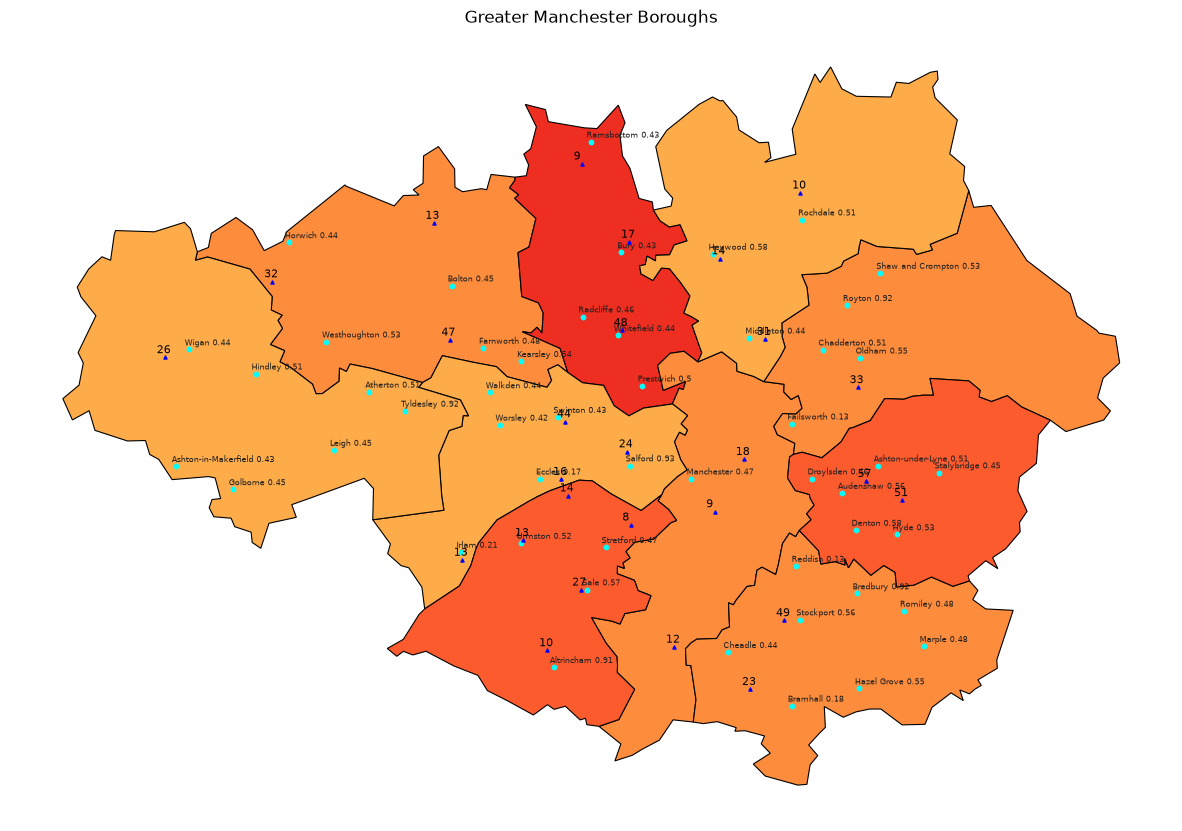

In [285]:
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from matplotlib.collections import PatchCollection
import matplotlib.colors as mcolors

from collections import defaultdict

import allocator as al

allocations = al.get_allocations()

place_probabilities = defaultdict(list)

for item in probabilities:
    place_probabilities[item[2]].append(item[1])

borough_data = {
    place: round(sum(probabilities) / len(probabilities), 1)
    for place, probabilities in place_probabilities.items()
}

#A different colour for each borough
# borough_data = {
#     "Bolton": 0.5,
#     "Bury": 0.1,
#     "Manchester": 0.9,
#     "Oldham": 0.3,
#     "Rochdale": 0.6,
#     "Salford": 0.8,
#     "Stockport": 0.0,
#     "Tameside": 1.0,
#     "Trafford": 0.9,
#     "Wigan": 0.2
# }

cmap = plt.cm.YlOrRd

fig, ax = plt.subplots(figsize=(15, 15))

for feature in data["features"]:
    name = feature["properties"]["LAD26NM"]
    geometry = feature["geometry"]

    if geometry["type"] == "Polygon":
        polygons = [geometry["coordinates"]]
    elif geometry["type"] == "MultiPolygon":
        polygons = geometry["coordinates"]
    else:
        continue

    for polygon in polygons:
        patch = Polygon(
            polygon[0],
            closed=True,
            facecolor=cmap(borough_data.get(name, "lightgrey")),
            edgecolor="black",
            linewidth=0.8
        )
        ax.add_patch(patch)


locations = []

with open("towndata.csv", "r") as f:
    locations = list(csv.reader(f))[1:]

for i, location in enumerate(locations):
    ax.scatter(float(location[3]), float(location[2]), color="cyan", marker="o", s=10)
    ax.annotate(str(location[0])+" "+str(round(probabilities[i][1], 2)), (float(location[3]), float(location[2])), fontsize=6, color="#202020", xytext=(-3, 3), textcoords="offset points")

for station in allocations:
    ax.scatter(float(station.coordinates[1]), float(station.coordinates[0]) - 0.00005, color="blue", marker="^", s=5, zorder=10)
    ax.annotate(str(station.allocation), (float(station.coordinates[1]), float(station.coordinates[0])), fontsize=8, color="black", xytext=(-6, 3), textcoords="offset points")


ax.autoscale_view()
ax.set_aspect(1.56)
ax.axis("off")
ax.set_title("Greater Manchester Boroughs")

plt.show()